# Proyecto Capstone: Clasificación Inteligente de Residuos Reciclables mediante Visión por Computadora (YOLOv11)

**Metodología:** CRISP-DM · **Modelo:** YOLO11n (Ultralytics) · **Clases:** Aluminio, Cartón, Plástico

| Fase | Contenido |
|---|---|
| 1 | Entendimiento del negocio |
| 2 | Entendimiento de los datos (EDA) |
| 3 | Preparación de los datos |
| 4 | Modelado |
| 5 | Evaluación |
| 6 | Despliegue (inferencia, ONNX, latencia y registro de inferencias en la base de datos EcoScan) |
| 7 | Conclusiones y trabajo futuro |

> **Cómo ejecutarlo:** en Google Colab con GPU, de arriba hacia abajo y sin saltarse celdas. Los resultados numéricos de la Fase 7 se generan automáticamente a partir de la corrida actual.

## 1. Fase 1: Entendimiento del Negocio (CRISP-DM)

### 1.1 Contexto y Problemática
La baja tasa de valorización de residuos domiciliarios e industriales se debe, en gran medida, a la incorrecta separación en origen por parte de los usuarios (contaminación cruzada en puntos limpios). Automatizar la identificación de materiales reciclables mediante visión artificial permite asistir a los usuarios en tiempo real e incrementar la eficiencia del reciclaje.

### 1.2 Objetivos del Negocio
* **Objetivo General:** Desarrollar e integrar un sistema de detección y clasificación automática de residuos reciclables (**Aluminio**, **Cartón** y **Plástico**) utilizando redes neuronales profundas para facilitar la separación en origen.
* **Objetivos Específicos:**
  1. Construir y curar un dataset etiquetado representativo de las tres clases objetivo.
  2. Entrenar un modelo ligero de detección de objetos capaz de ejecutarse con baja latencia en una aplicación web o dispositivo móvil.

### 1.3 Criterios de Éxito Técnico (Data Mining Goals)
* **Precisión de Detección (`mAP@50`):** Alcanzar un `mAP50` global $\ge 0.65$ en el conjunto de validación/prueba.
* **Velocidad de Inferencia:** Tiempo de inferencia inferior a $100\text{ ms}$ por imagen en GPU/CPU para permitir respuesta casi en tiempo real.

Ambos criterios se verifican de forma explícita en las Fases 5 y 6, y se resumen en la Fase 7.

In [1]:
# Instalación de dependencias
!pip install -q roboflow ultralytics opencv-python matplotlib pyyaml pandas pymysql

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 58.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.8 MB/s eta 0:00:00


In [2]:
import os, glob, time, yaml
from collections import Counter
from getpass import getpass

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display, Markdown
from ultralytics import YOLO

# Criterios de éxito definidos en la Fase 1 (se usan en las Fases 5, 6 y 7)
MAP50_OBJETIVO = 0.65
LATENCIA_OBJETIVO_MS = 100

print("Dispositivo:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Dispositivo: Tesla T4


In [3]:
# Descarga del dataset desde Roboflow.
# La API key NO va escrita en el notebook: se lee de los Secrets de Colab (ROBOFLOW_API_KEY),
# de una variable de entorno, o se pide por teclado.
def obtener_api_key():
    try:
        from google.colab import userdata
        return userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        return os.environ.get("ROBOFLOW_API_KEY") or getpass("API key de Roboflow: ")

dataset_path = "/content/Capstone-1"

if not os.path.exists(f"{dataset_path}/data.yaml"):
    print("Descargando dataset desde Roboflow...")
    from roboflow import Roboflow
    rf = Roboflow(api_key=obtener_api_key())
    project = rf.workspace("emanuel-leonardo-mejias-torres").project("capstone-s2mpp")
    dataset = project.version(1).download("yolov11")
    dataset_path = dataset.location
else:
    print("Dataset ya presente en la ruta local.")

with open(f"{dataset_path}/data.yaml", "r") as f:
    data_yaml = yaml.safe_load(f)

CLASES = data_yaml["names"]

def nombre_clase(i):
    return CLASES[i] if isinstance(CLASES, list) else CLASES.get(i, str(i))

print("Clases:", [nombre_clase(i) for i in range(len(CLASES))])

Descargando dataset desde Roboflow...
API key de Roboflow: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Capstone-1 in yolov11:: 100%|██████████| 1909/1909 [00:00<00:00, 8159.60it/s]

Clases: ['Aluminio', 'Carton', 'Plastico']


## 2. Fase 2: Entendimiento de los Datos (EDA)

En esta fase se analiza la distribución de clases e instancias, el formato de las anotaciones, la geometría de las cajas (escala MS-COCO y relación de aspecto) y la distribución espacial de los objetos en el encuadre.

Las celdas de esta fase **solo leen** los archivos de etiquetas (no los modifican). Cuando una anotación viene como polígono, se calcula su caja envolvente en memoria para que ningún análisis excluya esas instancias.

Split   Imágenes  Instancias      Polígonos
train        860        1456      628 (43%)
valid         61         109       44 (40%)
test          31          61       23 (38%)

Instancias por clase:
  Aluminio  train:  316 (21.7%) | valid:  16
  Carton    train:  572 (39.3%) | valid:  51
  Plastico  train:  568 (39.0%) | valid:  42


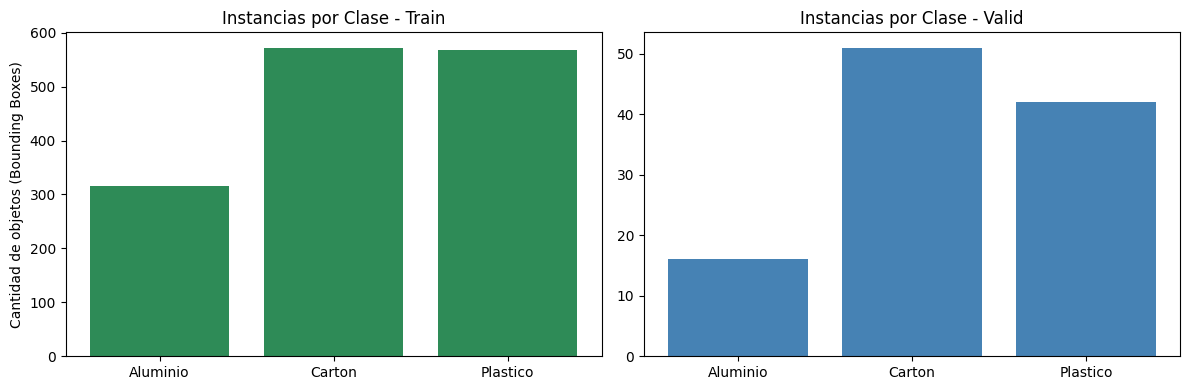

In [4]:
def listar_imagenes(split):
    exts = (".jpg", ".jpeg", ".png")
    return sorted(p for p in glob.glob(f"{dataset_path}/{split}/images/*") if p.lower().endswith(exts))

def leer_etiquetas_archivo(ruta_txt):
    """Devuelve [(cls, xc, yc, w, h, es_poligono)]. Los polígonos se convierten a su caja envolvente (solo en memoria)."""
    registros = []
    with open(ruta_txt, "r") as f:
        for linea in f:
            v = [float(x) for x in linea.split()]
            if len(v) < 5:
                continue
            cls = int(v[0])
            if len(v) == 5:
                registros.append((cls, v[1], v[2], v[3], v[4], False))
            else:
                xs, ys = v[1::2], v[2::2]
                x0, x1 = max(0.0, min(xs)), min(1.0, max(xs))
                y0, y1 = max(0.0, min(ys)), min(1.0, max(ys))
                registros.append((cls, (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0, True))
    return registros

def leer_etiquetas(split):
    registros = []
    for txt in sorted(glob.glob(f"{dataset_path}/{split}/labels/*.txt")):
        registros.extend(leer_etiquetas_archivo(txt))
    return registros

etiquetas = {s: leer_etiquetas(s) for s in ("train", "valid", "test")}

# 1. Tamaño de cada partición y formato de las anotaciones
print(f"{'Split':<6} {'Imágenes':>9} {'Instancias':>11} {'Polígonos':>14}")
for s, reg in etiquetas.items():
    n_poly = sum(r[5] for r in reg)
    pct = 100 * n_poly / len(reg) if reg else 0
    print(f"{s:<6} {len(listar_imagenes(s)):>9} {len(reg):>11} {n_poly:>8} ({pct:.0f}%)")

# 2. Distribución por clase
nombres = [nombre_clase(i) for i in range(len(CLASES))]
train_counts = Counter(nombre_clase(r[0]) for r in etiquetas["train"])
val_counts = Counter(nombre_clase(r[0]) for r in etiquetas["valid"])
total_tr = sum(train_counts.values())

print("\nInstancias por clase:")
for n in nombres:
    print(f"  {n:<9} train: {train_counts[n]:>4} ({100 * train_counts[n] / total_tr:.1f}%) | valid: {val_counts[n]:>3}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(nombres, [train_counts[n] for n in nombres], color="seagreen")
ax[0].set_title("Instancias por Clase - Train")
ax[0].set_ylabel("Cantidad de objetos (Bounding Boxes)")
ax[1].bar(nombres, [val_counts[n] for n in nombres], color="steelblue")
ax[1].set_title("Instancias por Clase - Valid")
plt.tight_layout()
plt.show()

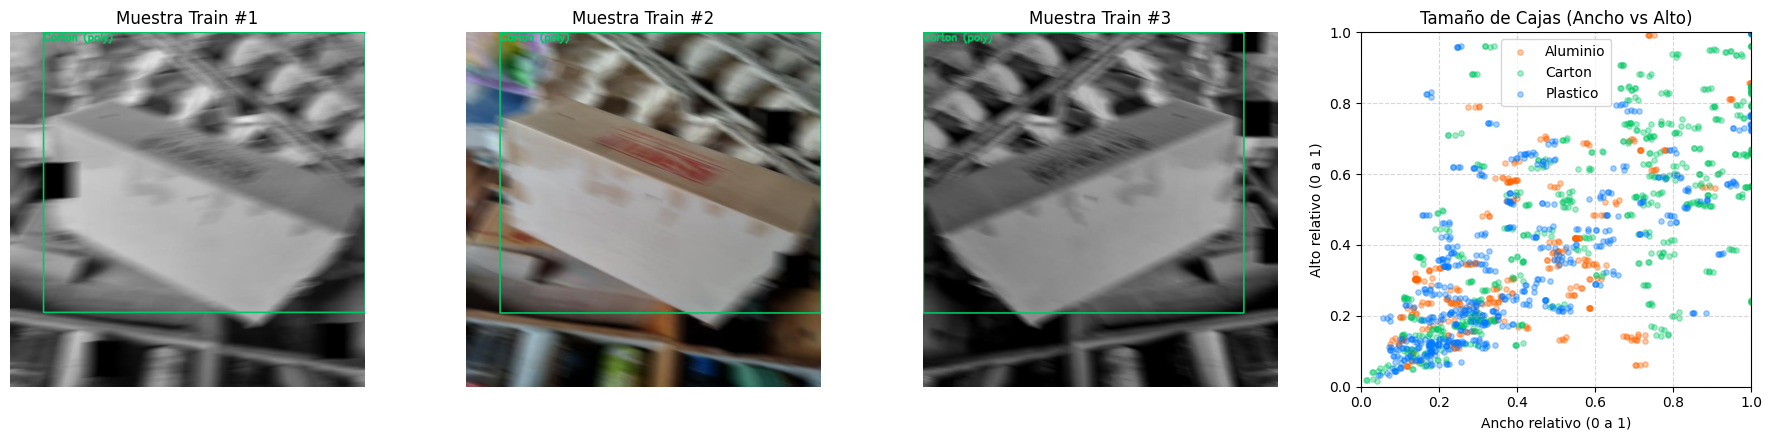

In [5]:
# Inspección visual (3 imágenes de train con sus cajas) y dispersión de tamaños de caja por clase
colores_rgb = [(255, 100, 0), (0, 200, 100), (0, 120, 255)]
muestras = listar_imagenes("train")[:3]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for idx, (ax, img_path) in enumerate(zip(axes[:3], muestras)):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    txt = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    if os.path.exists(txt):
        for cls, xc, yc, bw, bh, es_poly in leer_etiquetas_archivo(txt):
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
            col = colores_rgb[cls % len(colores_rgb)]
            cv2.rectangle(img, (x1, y1), (x2, y2), col, 2)
            cv2.putText(img, nombre_clase(cls) + (" (poly)" if es_poly else ""),
                        (x1, max(y1 - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
    ax.imshow(img)
    ax.set_title(f"Muestra Train #{idx + 1}")
    ax.axis("off")

ax_size = axes[3]
for i, n in enumerate(nombres):
    pts = [(r[3], r[4]) for r in etiquetas["train"] if r[0] == i]
    if pts:
        c = tuple(v / 255 for v in colores_rgb[i % len(colores_rgb)])
        ax_size.scatter(*zip(*pts), alpha=0.35, s=15, color=c, label=n)
ax_size.set_title("Tamaño de Cajas (Ancho vs Alto)")
ax_size.set_xlabel("Ancho relativo (0 a 1)")
ax_size.set_ylabel("Alto relativo (0 a 1)")
ax_size.set_xlim(0, 1); ax_size.set_ylim(0, 1)
ax_size.grid(True, linestyle="--", alpha=0.5)
ax_size.legend()
plt.tight_layout()
plt.show()

### 2.1 Categorización por escala MS-COCO y relación de aspecto

En visión por computadora los objetos se clasifican según el estándar **MS-COCO** (sobre una grilla de $640 \times 640$ px): pequeños $< 32^2$ px, medianos entre $32^2$ y $96^2$ px, y grandes $> 96^2$ px. Complementariamente se estudia la relación de aspecto $\text{Ratio} = \frac{\text{Ancho}}{\text{Alto}}$ para caracterizar la geometría de las cajas que debe predecir el cabezal de detección (*anchor-free*, con DFL).

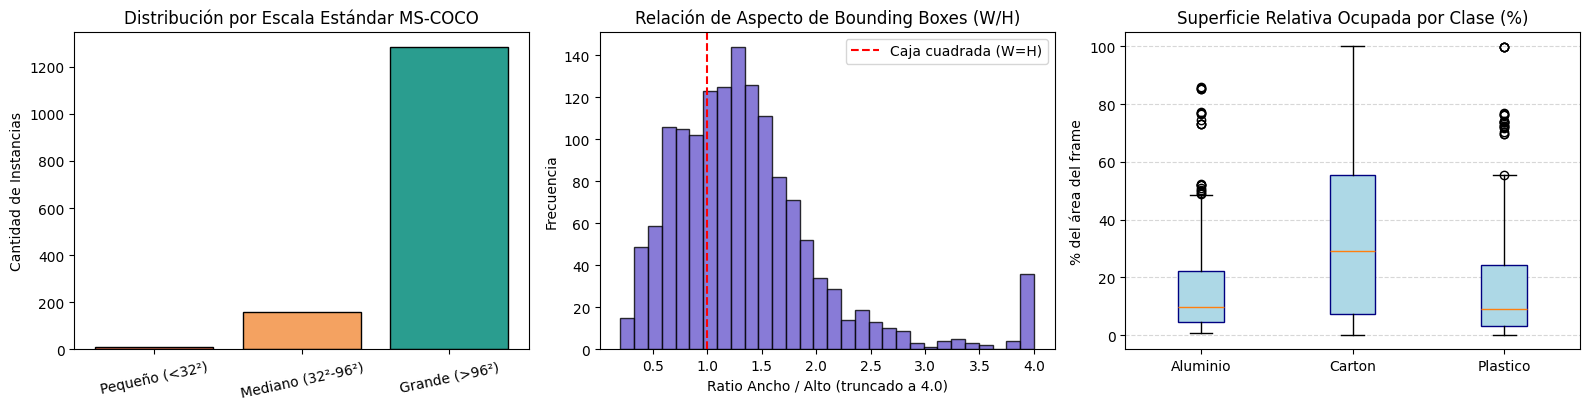

**Resumen geométrico (train, 1456 cajas, incluyendo polígonos convertidos):** escala predominante: *Grande (>96²)* (88%); relación de aspecto mediana W/H = 1.26; clase con mayor superficie mediana: *Carton* (29.1% del frame).

In [6]:
IMG_SIZE = 640
validos = [r for r in etiquetas["train"] if r[3] > 0 and r[4] > 0]

areas = np.array([(r[3] * IMG_SIZE) * (r[4] * IMG_SIZE) for r in validos])
ratios = np.array([r[3] / r[4] for r in validos])
escalas = {
    "Pequeño (<32²)":    int((areas < 32 ** 2).sum()),
    "Mediano (32²-96²)": int(((areas >= 32 ** 2) & (areas <= 96 ** 2)).sum()),
    "Grande (>96²)":     int((areas > 96 ** 2).sum()),
}
areas_clase = {n: [r[3] * r[4] * 100 for r in validos if nombre_clase(r[0]) == n] for n in nombres}  # % del frame

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

ax[0].bar(escalas.keys(), escalas.values(), color=["#e76f51", "#f4a261", "#2a9d8f"], edgecolor="black")
ax[0].set_title("Distribución por Escala Estándar MS-COCO")
ax[0].set_ylabel("Cantidad de Instancias")
ax[0].tick_params(axis="x", rotation=12)

ax[1].hist(np.clip(ratios, 0, 4), bins=30, color="slateblue", edgecolor="black", alpha=0.8)
ax[1].axvline(1.0, color="red", linestyle="--", label="Caja cuadrada (W=H)")
ax[1].set_title("Relación de Aspecto de Bounding Boxes (W/H)")
ax[1].set_xlabel("Ratio Ancho / Alto (truncado a 4.0)")
ax[1].set_ylabel("Frecuencia")
ax[1].legend()

bp = ax[2].boxplot(list(areas_clase.values()), patch_artist=True,
                   boxprops=dict(facecolor="lightblue", color="navy"))
ax[2].set_xticks(range(1, len(nombres) + 1))
ax[2].set_xticklabels(areas_clase.keys())
ax[2].set_title("Superficie Relativa Ocupada por Clase (%)")
ax[2].set_ylabel("% del área del frame")
ax[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Resumen numérico generado a partir de los datos (se usa para redactar los hallazgos)
dominante = max(escalas, key=escalas.get)
mediana_area = {n: (float(np.median(v)) if v else float("nan")) for n, v in areas_clase.items()}
mayor_sup = max(mediana_area, key=mediana_area.get)
display(Markdown(
    f"**Resumen geométrico (train, {len(validos)} cajas, incluyendo polígonos convertidos):** "
    f"escala predominante: *{dominante}* ({100 * escalas[dominante] / len(validos):.0f}%); "
    f"relación de aspecto mediana W/H = {np.median(ratios):.2f}; "
    f"clase con mayor superficie mediana: *{mayor_sup}* ({mediana_area[mayor_sup]:.1f}% del frame)."
))

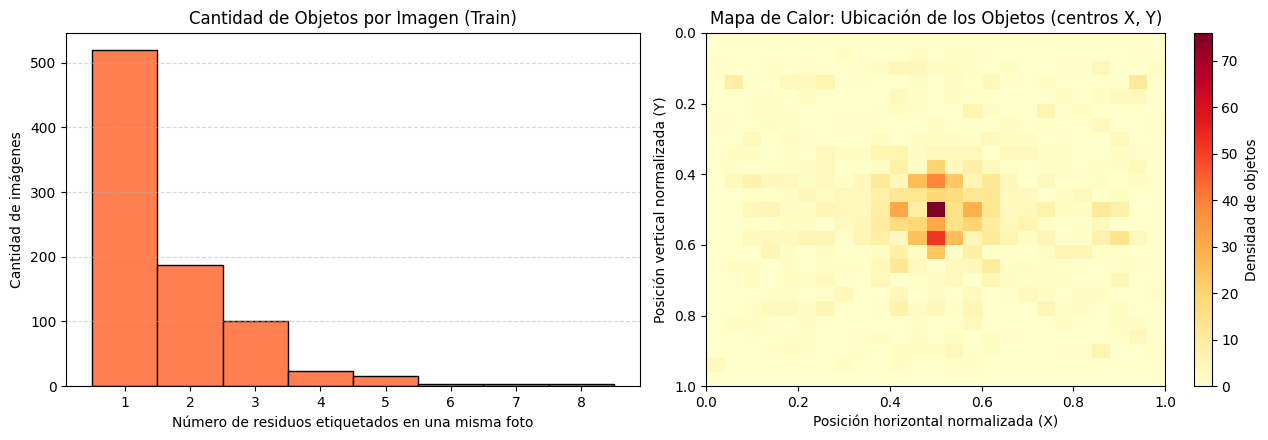

Promedio de objetos por imagen: 1.69 (máximo: 8)


In [7]:
# Densidad de objetos por imagen y mapa de calor de su ubicación en el encuadre
objetos_por_imagen = [len(leer_etiquetas_archivo(t)) for t in glob.glob(f"{dataset_path}/train/labels/*.txt")]
objetos_por_imagen = [n for n in objetos_por_imagen if n > 0]
centros_x = [r[1] for r in etiquetas["train"]]
centros_y = [r[2] for r in etiquetas["train"]]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].hist(objetos_por_imagen, bins=range(1, max(objetos_por_imagen) + 2), color="coral", edgecolor="black", align="left")
ax[0].set_title("Cantidad de Objetos por Imagen (Train)")
ax[0].set_xlabel("Número de residuos etiquetados en una misma foto")
ax[0].set_ylabel("Cantidad de imágenes")
ax[0].grid(axis="y", linestyle="--", alpha=0.5)

hb = ax[1].hist2d(centros_x, centros_y, bins=25, cmap="YlOrRd", range=[[0, 1], [0, 1]])
ax[1].invert_yaxis()  # (0,0) arriba a la izquierda, como en las coordenadas de imagen
ax[1].set_title("Mapa de Calor: Ubicación de los Objetos (centros X, Y)")
ax[1].set_xlabel("Posición horizontal normalizada (X)")
ax[1].set_ylabel("Posición vertical normalizada (Y)")
plt.colorbar(hb[3], ax=ax[1], label="Densidad de objetos")

plt.tight_layout()
plt.show()
print(f"Promedio de objetos por imagen: {np.mean(objetos_por_imagen):.2f} (máximo: {max(objetos_por_imagen)})")

### 2.2 Hallazgos del EDA

El dataset descargado desde Roboflow contiene `860` imágenes de entrenamiento y `61` de validación.

1. **Desbalance de clases.**
   * *Train* (`1,456` instancias): **Cartón** `572` (39.3 %) y **Plástico** `568` (39.0 %) están en paridad; **Aluminio** tiene menor representación, `316` instancias (21.7 %).
   * *Valid* (`109` instancias): se mantiene la proporción, con `51` de Cartón, `42` de Plástico y solo `16` de Aluminio. Con tan pocas instancias de Aluminio, las métricas de esa clase tendrán alta varianza.
2. **Formato mixto de anotaciones (hallazgo crítico).** Hay cajas (5 valores por fila) mezcladas con polígonos de segmentación: `628` filas en *train* (43 % de sus instancias) y `44` en *valid*. En las versiones recientes de Ultralytics, un archivo que combina ambos formatos es rechazado por el cargador de datos, por lo que se podía perder una fracción importante del dataset. Se corrige en la Fase 3.
3. **Variabilidad intraclase (hipótesis cualitativa).** Plástico reúne objetos de apariencia muy variable (botellas PET transparentes, deformaciones, reflejos), lo que anticipa que será la clase más difícil. Se contrasta con las métricas en la Fase 5.
4. **Geometría y distribución espacial.** La escala dominante, la relación de aspecto y la superficie relativa por clase se resumen numéricamente bajo los gráficos de la sección 2.1. El mapa de calor muestra en qué zona del encuadre se concentran los objetos.

## 3. Fase 3: Preparación de los Datos

### 3.1 Estandarización de etiquetas (polígonos → Bounding Boxes)
Para que el motor de entrenamiento no rechace los archivos con formato mixto, cada polígono se reemplaza por su **caja envolvente mínima** en el formato YOLO normalizado $(x_c, y_c, w, h)$, recortada al rango $[0, 1]$. La conversión se aplica a *train*, *valid* y *test*, y es idempotente (si se re-ejecuta, no vuelve a modificar nada).

In [8]:
def convertir_poligonos_a_cajas(base_dir):
    archivos_mod, lineas_conv, lineas_tot = 0, 0, 0
    for split in ("train", "valid", "test"):
        for txt in glob.glob(f"{base_dir}/{split}/labels/*.txt"):
            with open(txt, "r") as f:
                lineas = f.readlines()
            nuevas, modificado = [], False
            for linea in lineas:
                v = [float(x) for x in linea.split()]
                if len(v) < 5:                       # fila vacía o inválida
                    modificado = modificado or len(v) > 0
                    continue
                lineas_tot += 1
                cls = int(v[0])
                if len(v) == 5:
                    nuevas.append(f"{cls} {v[1]:.6f} {v[2]:.6f} {v[3]:.6f} {v[4]:.6f}\n")
                else:                                 # polígono -> caja envolvente
                    xs, ys = v[1::2], v[2::2]
                    x0, x1 = max(0.0, min(xs)), min(1.0, max(xs))
                    y0, y1 = max(0.0, min(ys)), min(1.0, max(ys))
                    nuevas.append(f"{cls} {(x0 + x1) / 2:.6f} {(y0 + y1) / 2:.6f} {x1 - x0:.6f} {y1 - y0:.6f}\n")
                    modificado = True
                    lineas_conv += 1
            if modificado:
                with open(txt, "w") as f:
                    f.writelines(nuevas)
                archivos_mod += 1
    return {"archivos": archivos_mod, "poligonos": lineas_conv, "lineas": lineas_tot}

resumen_conversion = convertir_poligonos_a_cajas(dataset_path)
print(f"Archivos modificados: {resumen_conversion['archivos']} | "
      f"polígonos convertidos: {resumen_conversion['poligonos']} de {resumen_conversion['lineas']} filas totales.")
print("(Si re-ejecutas esta celda, reportará 0 porque las etiquetas ya están estandarizadas.)")

Archivos modificados: 485 | polígonos convertidos: 695 de 1626 filas totales.
(Si re-ejecutas esta celda, reportará 0 porque las etiquetas ya están estandarizadas.)


### 3.2 Oversampling de la clase minoritaria (Aluminio)
Aluminio representa solo el 21.7 % de las instancias de entrenamiento. Para aumentar su peso durante el entrenamiento, cada imagen de *train* que contiene al menos un objeto de Aluminio se duplica **volteada horizontalmente** (con $x_c \leftarrow 1 - x_c$ en sus etiquetas). La técnica se aplica **solo a *train***; *valid* y *test* no se tocan.

> **Alcance de esta técnica.** YOLO ya aplica volteo horizontal aleatorio durante el entrenamiento (`fliplr=0.5`), por lo que la copia no aporta información visual nueva: su efecto es aumentar la frecuencia con que se muestrean estas imágenes. Además, las copias incluyen también los objetos de otras clases presentes en esas fotos. Su efecto real **no se asume positivo**: se mide en la Fase 5 y se discute en la Fase 7. Se puede desactivar con `APLICAR_OVERSAMPLING = False` para comparar.

In [9]:
APLICAR_OVERSAMPLING = True

id_aluminio = next(i for i in range(len(CLASES)) if "aluminio" in nombre_clase(i).lower())
nuevas_copias = 0

if APLICAR_OVERSAMPLING:
    for txt_path in sorted(glob.glob(f"{dataset_path}/train/labels/*.txt")):
        if "_oversample_alu" in txt_path:            # no volver a duplicar copias previas
            continue
        with open(txt_path, "r") as f:
            lineas = [l.split() for l in f if l.strip()]
        if not any(int(float(p[0])) == id_aluminio for p in lineas if len(p) == 5):
            continue

        base = txt_path.replace("/labels/", "/images/").rsplit(".", 1)[0]
        img_path = next((base + e for e in (".jpg", ".jpeg", ".png") if os.path.exists(base + e)), None)
        if img_path is None:
            continue

        ext = os.path.splitext(img_path)[1]
        cv2.imwrite(base + "_oversample_alu" + ext, cv2.flip(cv2.imread(img_path), 1))
        with open(txt_path.rsplit(".", 1)[0] + "_oversample_alu.txt", "w") as f_out:
            for p in lineas:
                if len(p) == 5:
                    cls = int(float(p[0]))
                    xc = 1.0 - float(p[1])
                    f_out.write(f"{cls} {xc:.6f} {float(p[2]):.6f} {float(p[3]):.6f} {float(p[4]):.6f}\n")
        nuevas_copias += 1

# Borrar caché para que YOLO relea el dataset actualizado
for cache_file in glob.glob(f"{dataset_path}/*/*.cache"):
    os.remove(cache_file)

# Distribución de clases efectiva con la que se entrenará
train_counts_post = Counter(nombre_clase(r[0]) for r in leer_etiquetas("train"))
total_post = sum(train_counts_post.values())
print(f"Imágenes de refuerzo agregadas: {nuevas_copias}\n")
print(f"{'Clase':<10} {'Antes':>6} {'Después':>8} {'% después':>10}")
for n in nombres:
    print(f"{n:<10} {train_counts[n]:>6} {train_counts_post[n]:>8} {100 * train_counts_post[n] / total_post:>9.1f}%")

Imágenes de refuerzo agregadas: 252

Clase       Antes  Después  % después
Aluminio      316      632      32.8%
Carton        572      620      32.2%
Plastico      568      672      34.9%


## 4. Fase 4: Modelado (Fine-Tuning de YOLO11n)

Se selecciona **YOLO11n (Nano)** y se aplica *transfer learning* desde los pesos preentrenados en COCO (`yolo11n.pt`). El entrenamiento usa 50 épocas, resolución $640 \times 640$, `batch=16` y `patience=15` (parada anticipada si la métrica de validación no mejora durante 15 épocas). El optimizador es `auto`: en esta configuración Ultralytics selecciona **AdamW** y calcula la tasa de aprendizaje inicial automáticamente (≈ 0.0014 para 3 clases).

### 4.1 Fundamentación arquitectónica
Se eligió la variante *nano* porque el objetivo de negocio exige baja latencia en aplicaciones web o móviles: tiene ≈ 2.59 M de parámetros y ≈ 6.5 GFLOPs. Frente a YOLOv8, YOLO11 introduce dos bloques relevantes:

1. **`C3k2`:** variante más eficiente del bloque CSP `C2f` de YOLOv8. El sufijo "2" hace referencia a que, como `C2f`, usa dos convoluciones de entrada/salida; internamente combina cuellos de botella o bloques `C3k` cuyo tamaño de kernel es configurable (3×3 por defecto). Reduce el costo computacional sin sacrificar capacidad de extracción de características.
2. **`C2PSA`:** módulo de atención espacial situado después de la capa `SPPF`. Permite a la red ponderar las regiones más informativas de la imagen, útil frente a fondos complejos.

### 4.2 Función de pérdida
El ajuste fino minimiza una pérdida ponderada con tres términos (pesos por defecto de Ultralytics, visibles en los argumentos del entrenamiento):

$$\mathcal{L}_{\text{total}} = \lambda_{\text{box}}\mathcal{L}_{\text{CIoU}} + \lambda_{\text{cls}}\mathcal{L}_{\text{BCE}} + \lambda_{\text{dfl}}\mathcal{L}_{\text{DFL}}$$

* $\mathcal{L}_{\text{CIoU}}$ (*Complete IoU*, $\lambda_{\text{box}} = 7.5$): penaliza el solapamiento, la distancia entre centros y la diferencia de relación de aspecto de las cajas.
* $\mathcal{L}_{\text{BCE}}$ (*Binary Cross-Entropy*, $\lambda_{\text{cls}} = 0.5$): evalúa la pertenencia a `Aluminio`, `Carton` y `Plastico`.
* $\mathcal{L}_{\text{DFL}}$ (*Distribution Focal Loss*, $\lambda_{\text{dfl}} = 1.5$): modela cada borde de la caja como una distribución en lugar de un valor único, lo que ayuda con límites difusos u objetos parcialmente ocluidos.

In [10]:
# Borrar caché previa para que YOLO cargue las etiquetas ya estandarizadas  esta es la apy key:SiHqMJp6DHgUgWyZcPV1
for cache_file in glob.glob(f"{dataset_path}/*/*.cache"):
    os.remove(cache_file)

model = YOLO("yolo11n.pt")

results = model.train(
    data=f"{dataset_path}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project="/content/runs/detect",
    name="ecoscan_yolo11n",
    exist_ok=True,
)

ruta_entreno = "/content/runs/detect/ecoscan_yolo11n"
df_res = pd.read_csv(f"{ruta_entreno}/results.csv")
df_res.columns = [c.strip() for c in df_res.columns]
print(f"Épocas ejecutadas: {len(df_res)} de 50")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Capstone-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ecoscan_yolo11n, nbs=64, nms=None, opset=None, optimize=False

## 5. Fase 5: Evaluación del Modelo

Se evalúa el mejor punto de control (`best.pt`) con Precisión ($P$), Recall ($R$), $F_1$, `mAP@50` y `mAP@50-95`, por clase y de forma global (promedio macro), junto con las curvas de entrenamiento y las matrices de confusión.

$$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

> **Nota metodológica.** `best.pt` se selecciona según el desempeño en *valid*, por lo que esa métrica es ligeramente optimista. Si el dataset incluye partición *test*, se evalúa una sola vez al final como estimación no sesgada. Ambas particiones son pequeñas (la clase Aluminio tiene solo 16 instancias en *valid*), así que las métricas por clase deben leerse con cautela.

In [11]:
best_model = YOLO(f"{ruta_entreno}/weights/best.pt")

def tabla_metricas(m):
    filas = []
    for i, nombre in m.names.items():
        p, r, ap50, ap = m.box.class_result(i)
        filas.append({"Clase": nombre, "Precision (P)": p, "Recall (R)": r,
                      "F1-Score": 2 * p * r / (p + r + 1e-8), "mAP@50": ap50, "mAP@50-95": ap})
    df = pd.DataFrame(filas)
    glob_row = {"Clase": "GLOBAL (promedio macro)"}
    glob_row.update({c: df[c].mean() for c in df.columns if c != "Clase"})
    return pd.concat([df, pd.DataFrame([glob_row])], ignore_index=True).round(3)

# Validación
metricas = best_model.val(data=f"{dataset_path}/data.yaml", split="val")
df_val = tabla_metricas(metricas)
print("\n=== MÉTRICAS EN VALIDACIÓN ===")
display(df_val)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1784.5±716.5 MB/s, size: 45.4 KB)
val: Scanning /content/Capstone-1/valid/labels.cache... 61 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 61/61 17.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7it/s 2.4s
                   all         61        109      0.792      0.577      0.646      0.407
              Aluminio         15         16          1      0.729       0.75       0.49
                Carton         32         51       0.79      0.549      0.691      0.489
              Plastico         27         42      0.585      0.452      0.498      0.242
Speed: 9.2ms preprocess, 8.2ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val

=== MÉTRICA

,Clase,Precision (P),Recall (R),F1-Score,mAP@50,mAP@50-95
0,Aluminio,1.000,0.729,0.843,0.750,0.490
1,Carton,0.790,0.549,0.648,0.691,0.489
2,Plastico,0.585,0.452,0.510,0.498,0.242
3,GLOBAL (promedio macro),0.792,0.577,0.667,0.646,0.407


In [12]:
# Evaluación en la partición de prueba (solo si existe)
hay_test = bool(listar_imagenes("test"))
if hay_test:
    metricas_test = best_model.val(data=f"{dataset_path}/data.yaml", split="test")
    df_test = tabla_metricas(metricas_test)
    print("\n=== MÉTRICAS EN TEST ===")
    display(df_test)
else:
    metricas_test, df_test = None, None
    print("El dataset no incluye partición de test con imágenes.")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1316.9±592.5 MB/s, size: 56.9 KB)
val: Scanning /content/Capstone-1/test/labels... 31 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 31/31 1.8Kit/s 0.0s
val: New cache created: /content/Capstone-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1it/s 1.9s
                   all         31         61      0.775      0.417      0.481      0.291
              Aluminio          8          8      0.823      0.587      0.603      0.436
                Carton         17         29      0.932      0.414      0.521      0.324
              Plastico         13         24       0.57       0.25      0.318      0.114
Speed: 9.0ms preprocess, 14.4ms inference, 0.0ms loss, 4.2ms postprocess per image

,Clase,Precision (P),Recall (R),F1-Score,mAP@50,mAP@50-95
0,Aluminio,0.823,0.587,0.685,0.603,0.436
1,Carton,0.932,0.414,0.573,0.521,0.324
2,Plastico,0.570,0.250,0.348,0.318,0.114
3,GLOBAL (promedio macro),0.775,0.417,0.535,0.481,0.291



📊 Curvas de pérdida y métricas por época


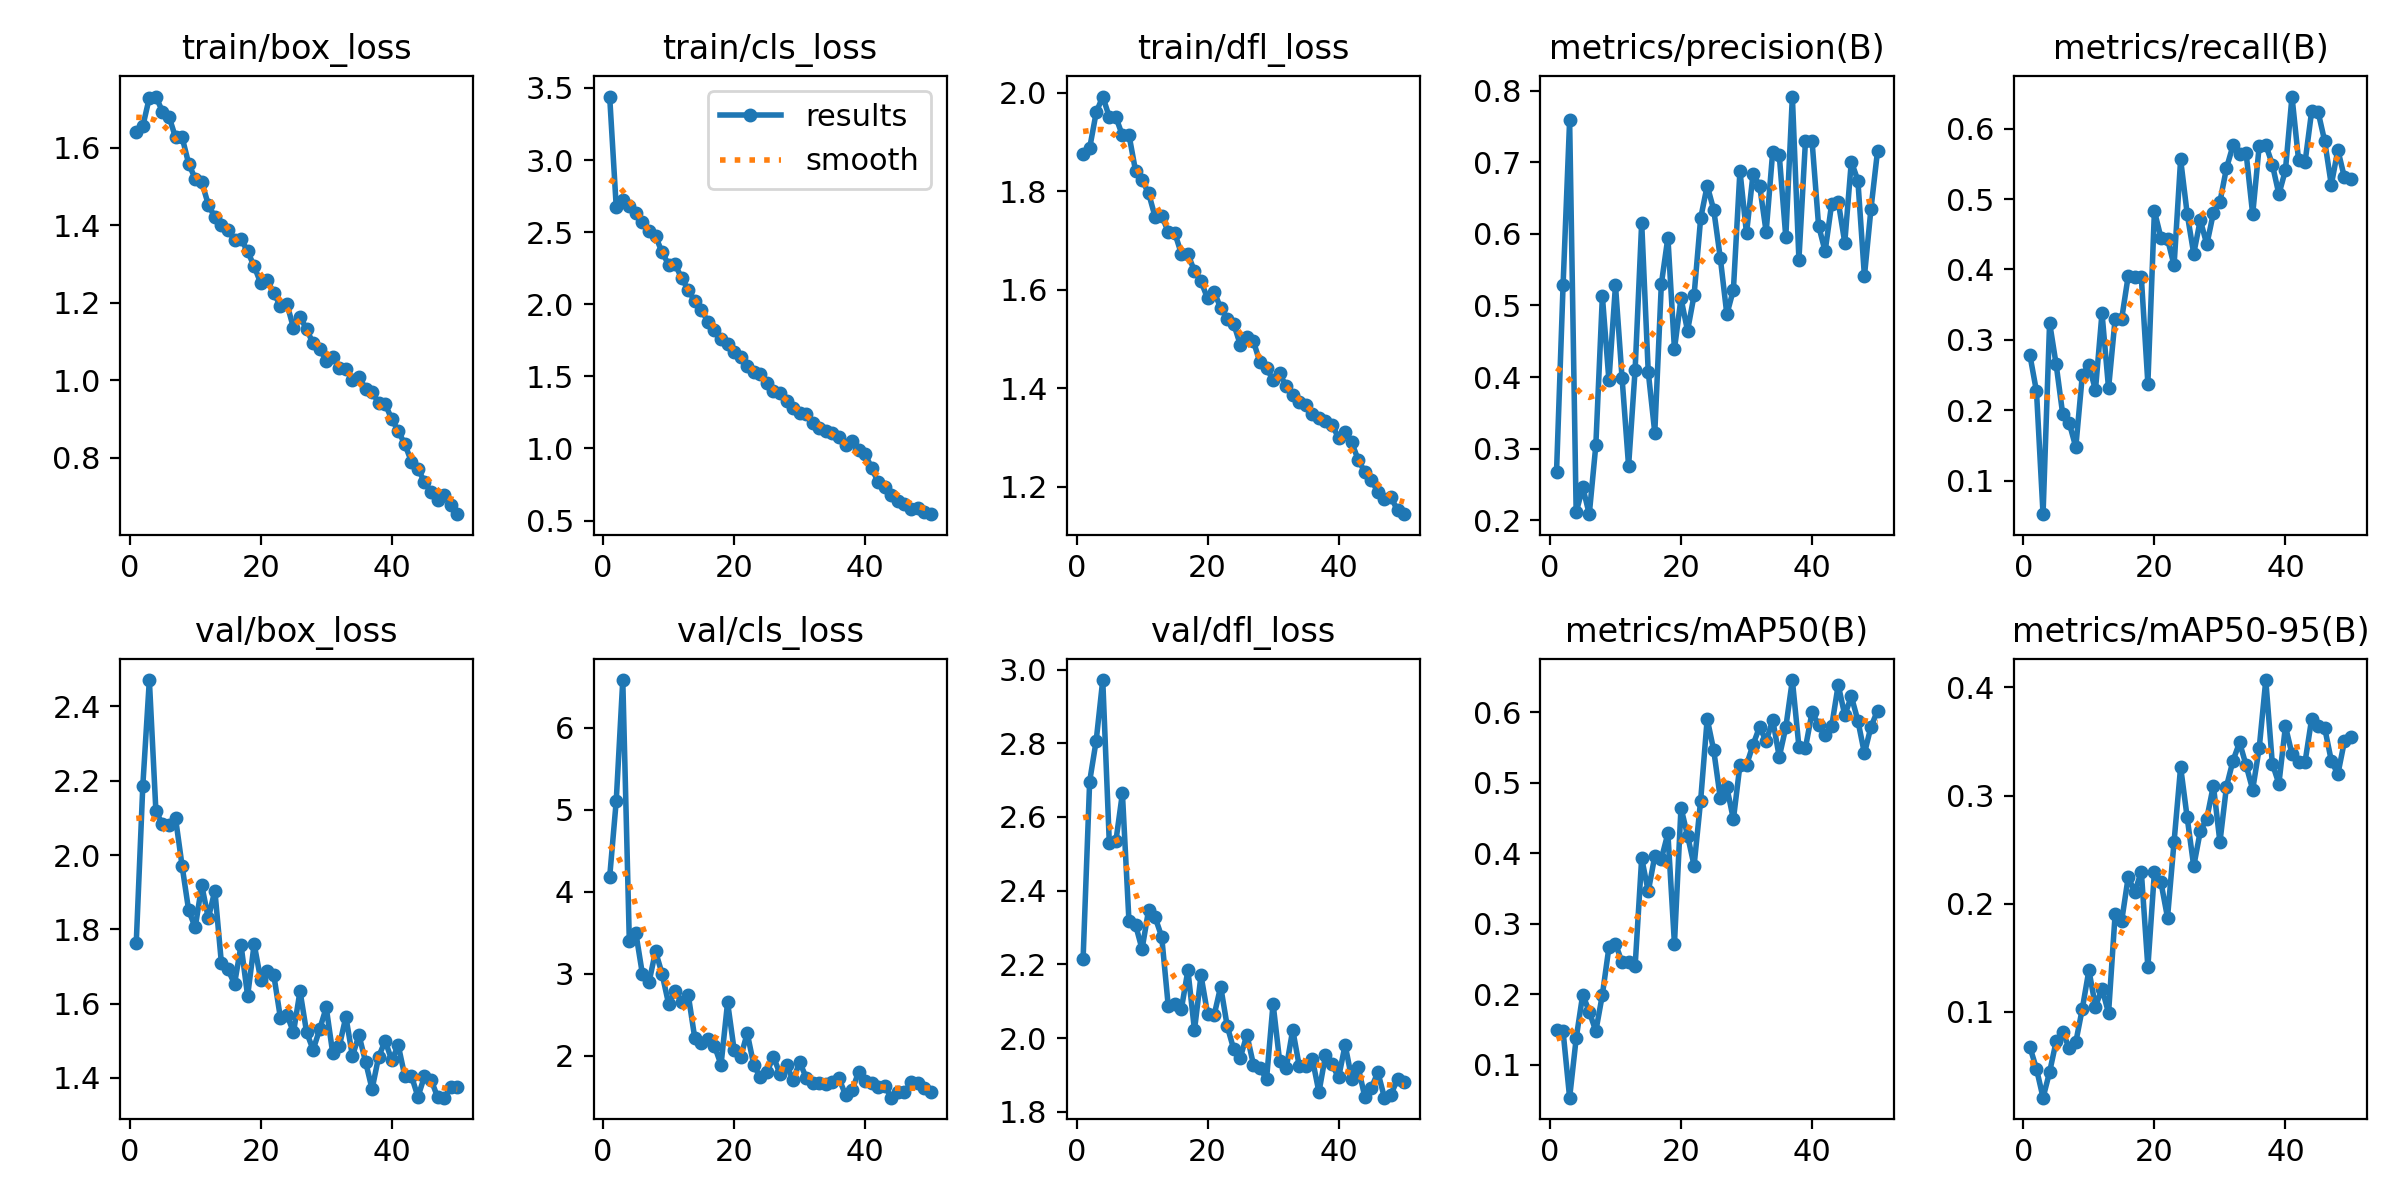


📊 Matriz de confusión (conteos)


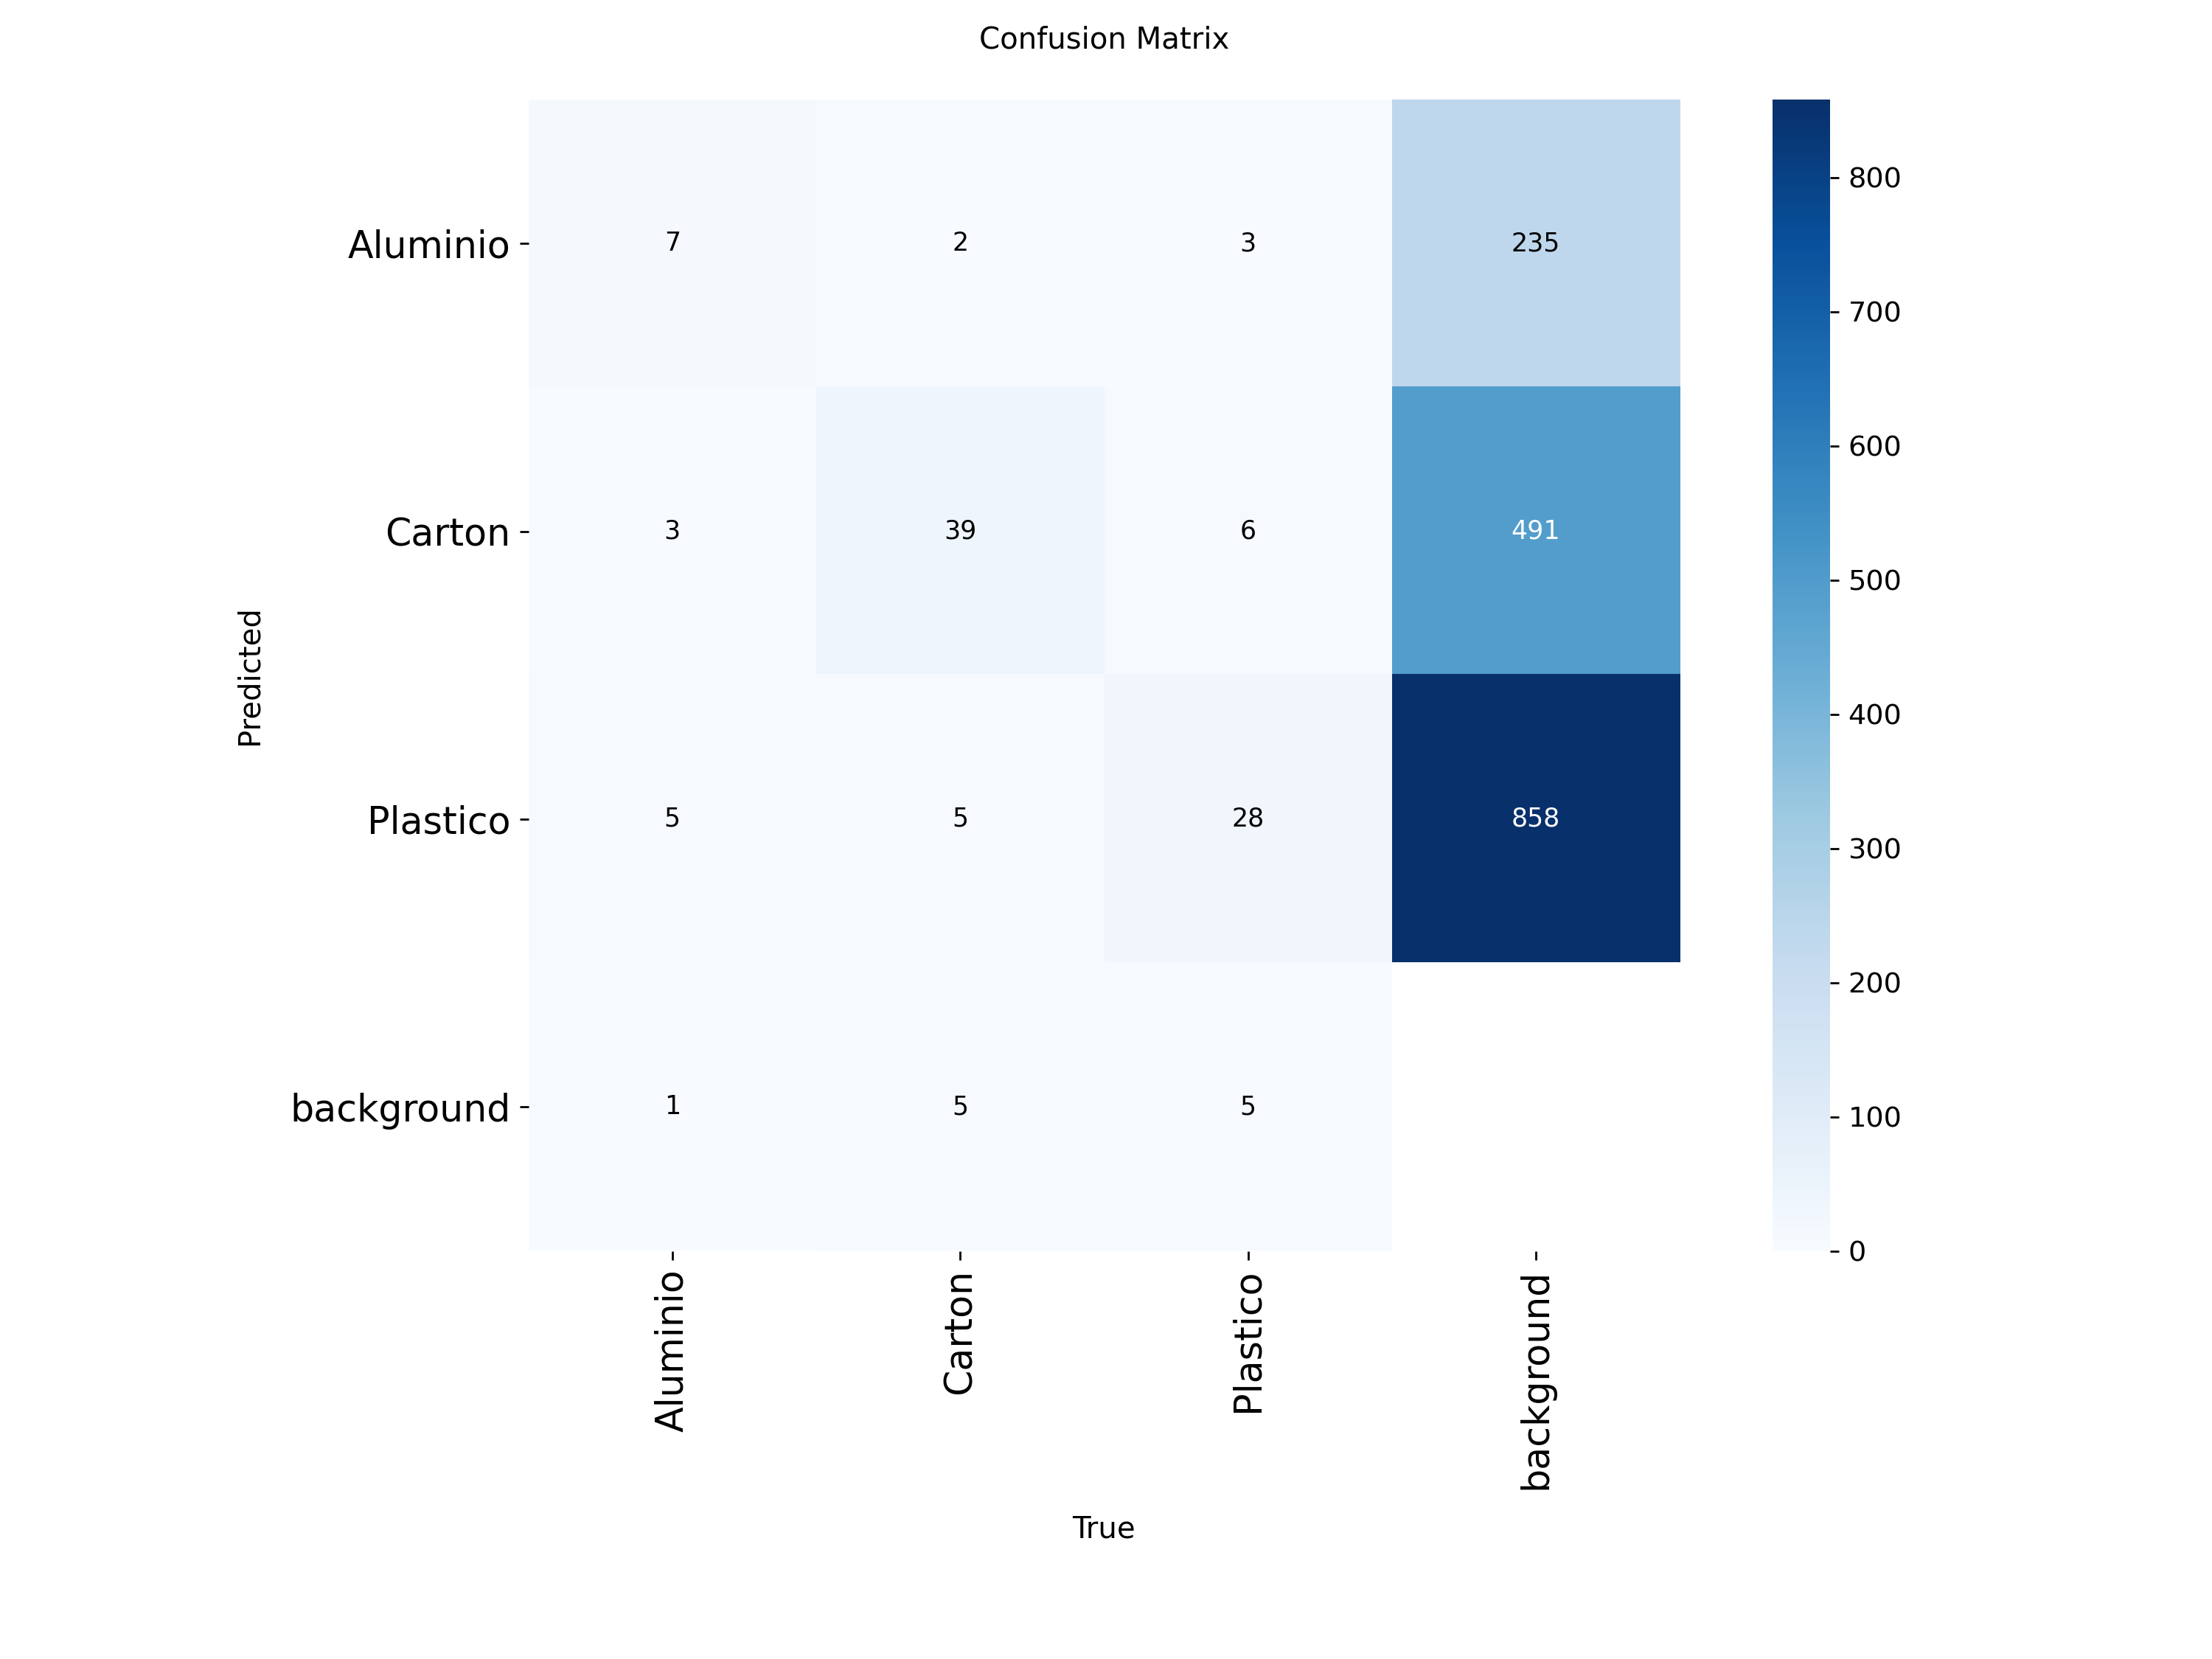


📊 Matriz de confusión normalizada


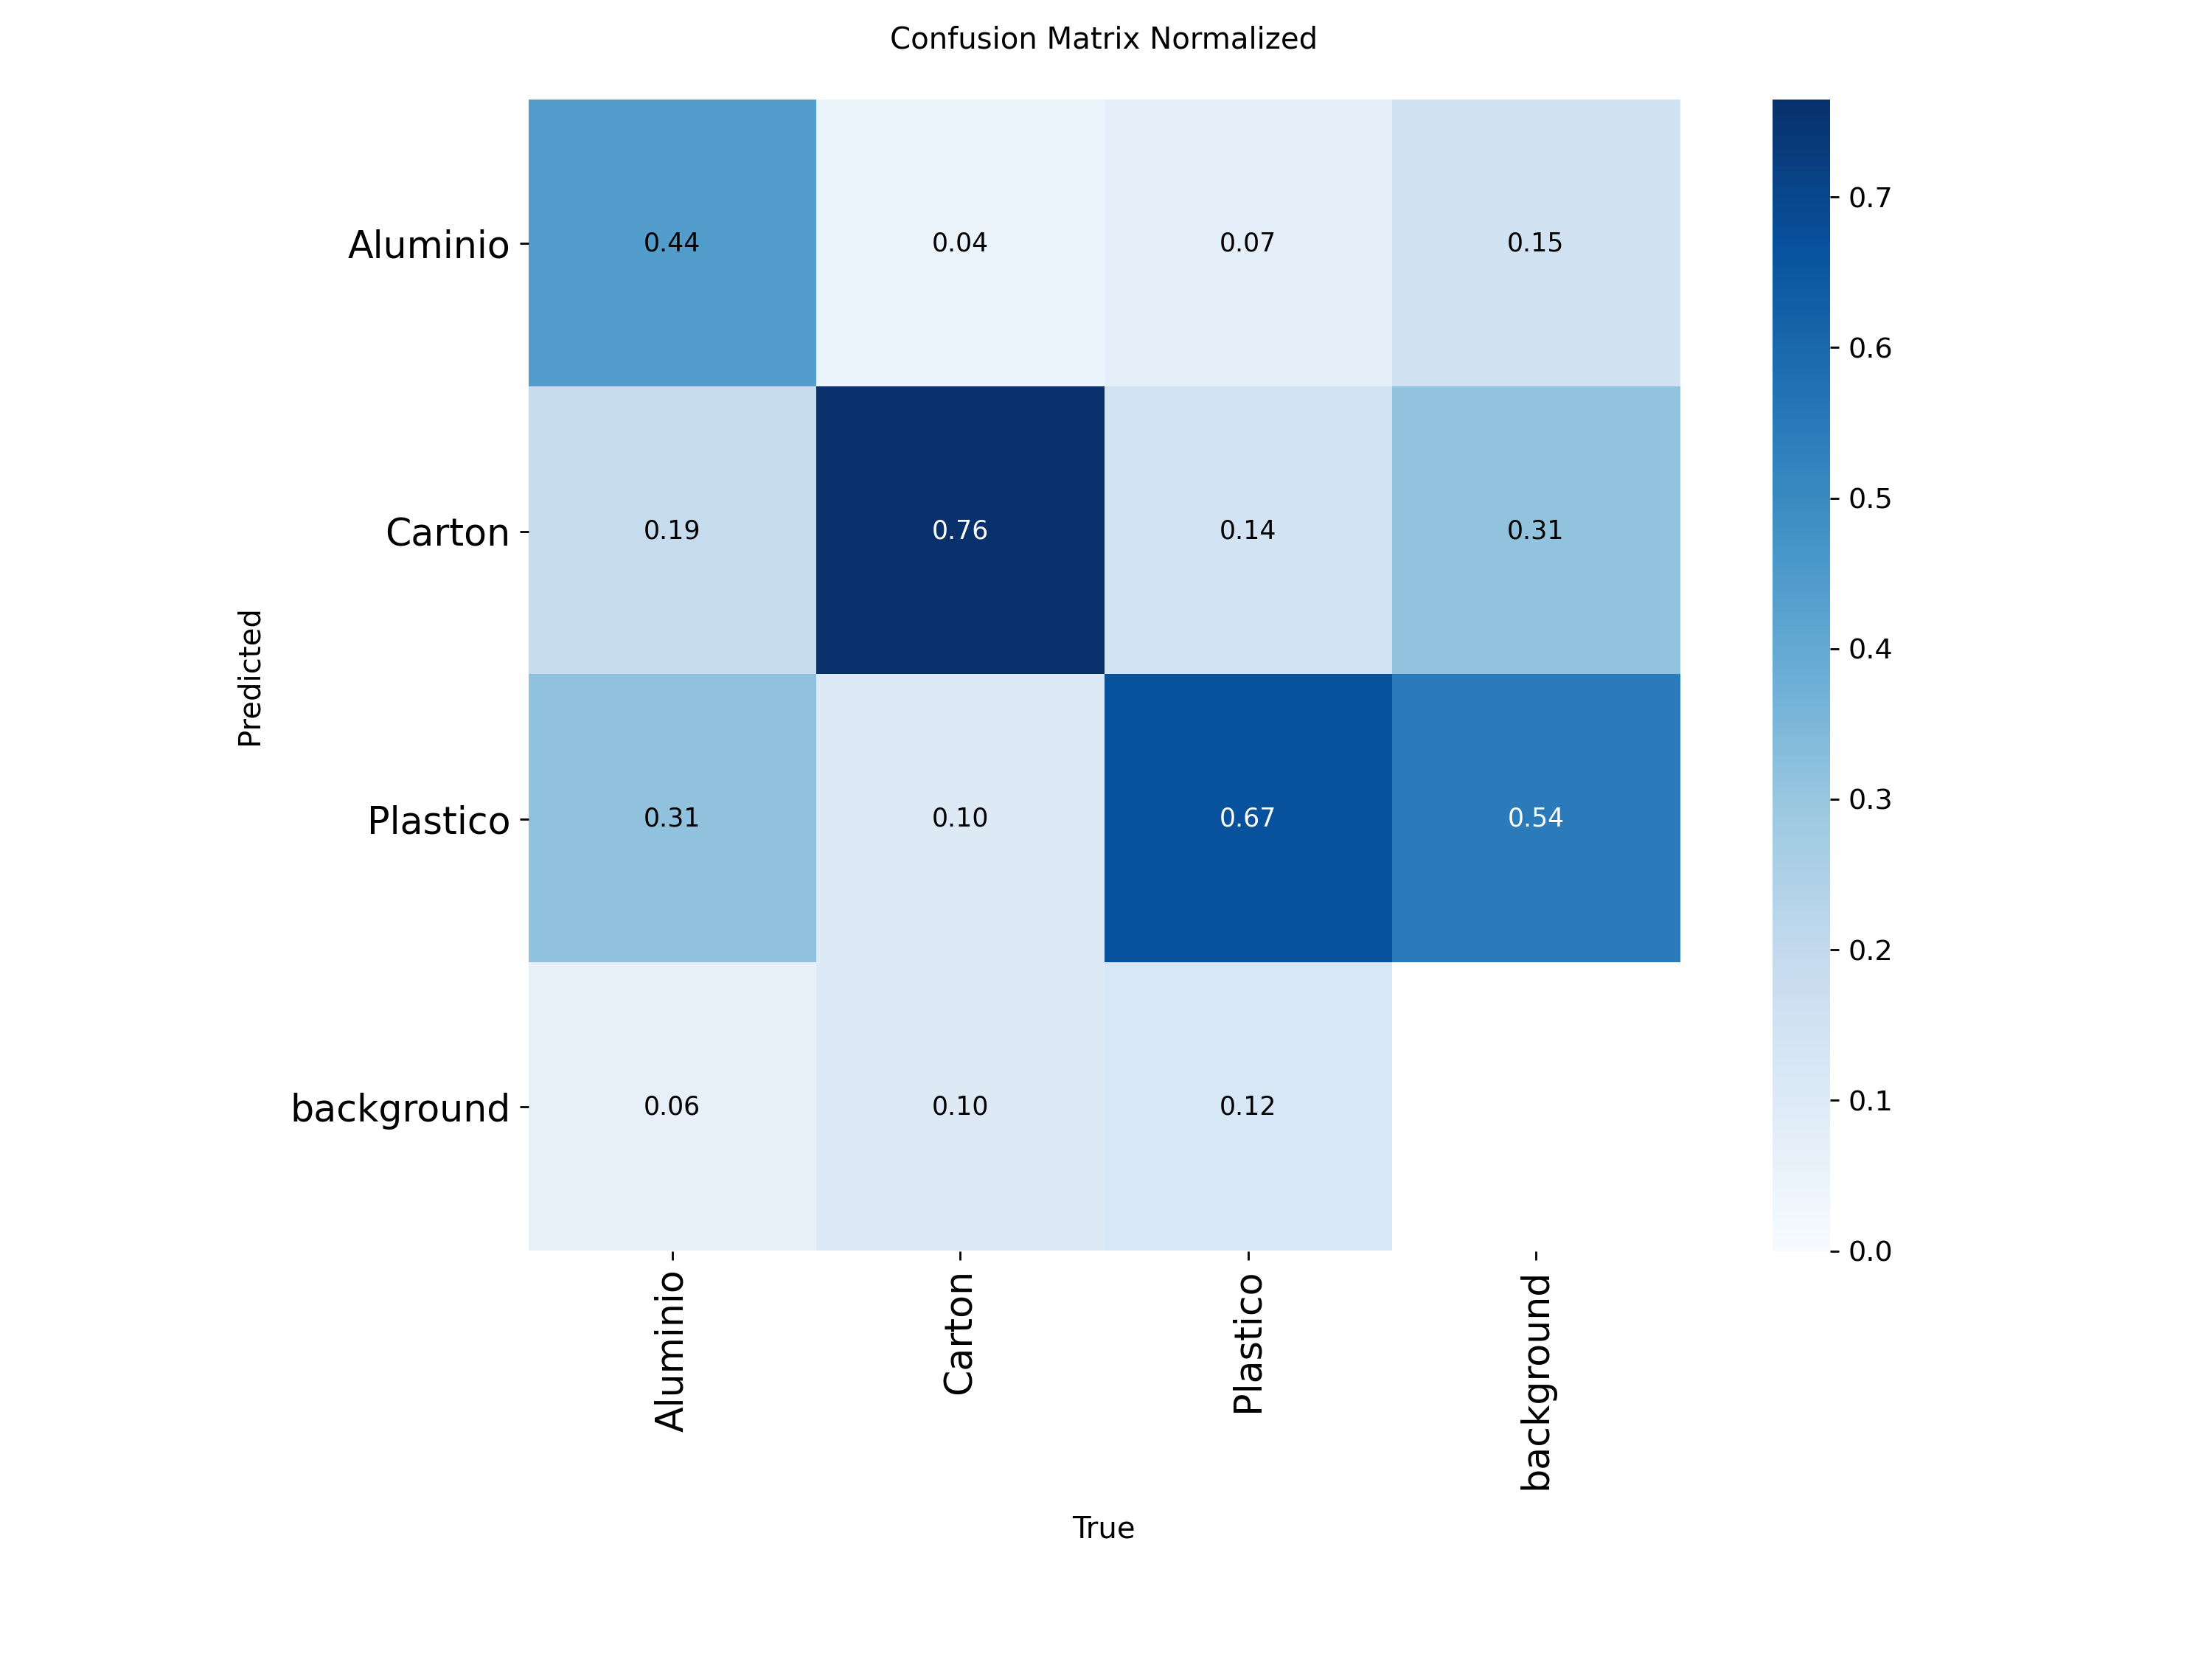

In [13]:
# Curvas de entrenamiento, matrices de confusión (conteo y normalizada) y curvas P-R / F1
graficos = [
    ("results.png", "Curvas de pérdida y métricas por época"),
    ("confusion_matrix.png", "Matriz de confusión (conteos)"),
    ("confusion_matrix_normalized.png", "Matriz de confusión normalizada"),
    ("PR_curve.png", "Curva Precisión-Recall"),
    ("F1_curve.png", "Curva F1 vs. umbral de confianza"),
]
for archivo, titulo in graficos:
    ruta = os.path.join(ruta_entreno, archivo)
    if os.path.exists(ruta):
        print(f"\n📊 {titulo}")
        display(Image(filename=ruta, width=750))

In [14]:
# Verificación explícita del criterio de éxito de precisión (Fase 1)
map50_val = float(metricas.box.map50)
print(f"mAP@50 global (valid): {map50_val:.3f} | objetivo ≥ {MAP50_OBJETIVO} → "
      f"{'✅ CUMPLE' if map50_val >= MAP50_OBJETIVO else '❌ NO CUMPLE'}")

if metricas_test is not None:
    map50_test = float(metricas_test.box.map50)
    print(f"mAP@50 global (test):  {map50_test:.3f} | objetivo ≥ {MAP50_OBJETIVO} → "
          f"{'✅ CUMPLE' if map50_test >= MAP50_OBJETIVO else '❌ NO CUMPLE'}")
else:
    map50_test = None

por_clase = df_val[df_val["Clase"] != "GLOBAL (promedio macro)"].set_index("Clase")["mAP@50"]
print(f"\nClase con mejor mAP@50: {por_clase.idxmax()} ({por_clase.max():.3f}) | "
      f"peor: {por_clase.idxmin()} ({por_clase.min():.3f})")

mAP@50 global (valid): 0.646 | objetivo ≥ 0.65 → ❌ NO CUMPLE
mAP@50 global (test):  0.481 | objetivo ≥ 0.65 → ❌ NO CUMPLE

Clase con mejor mAP@50: Aluminio (0.750) | peor: Plastico (0.498)


## 6. Fase 6: Despliegue (Inferencia, Exportación y Latencia)

Se comprueba el detector sobre imágenes de validación, se descargan los pesos (`best.pt`), se exporta el modelo al estándar **ONNX** y se mide la latencia de ambos formatos para verificar el criterio de velocidad de la Fase 1.

ONNX (*Open Neural Network Exchange*) desacopla el modelo de PyTorch y permite ejecutarlo con ONNX Runtime en backends como FastAPI, Flask, Node.js o Docker, incluso en CPU. La latencia depende del hardware donde se ejecute el notebook.

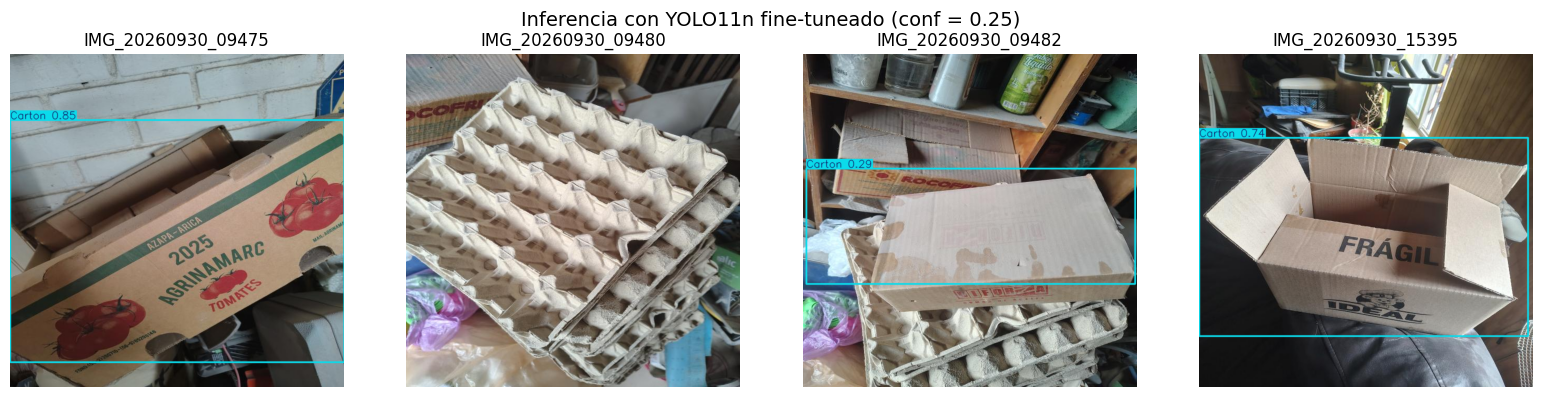

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# 1. Inferencia de ejemplo en 4 imágenes de validación
imgs_demo = listar_imagenes("valid")[:4]
fig, axes = plt.subplots(1, len(imgs_demo), figsize=(16, 4))
for ax, img_p in zip(np.atleast_1d(axes), imgs_demo):
    pred = best_model.predict(source=img_p, conf=0.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(img_p)[:18])
    ax.axis("off")
plt.suptitle("Inferencia con YOLO11n fine-tuneado (conf = 0.25)", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Descargar best.pt (solo en Colab)
peso_final = f"{ruta_entreno}/weights/best.pt"
try:
    from google.colab import files
    files.download(peso_final)
except ImportError:
    print("Fuera de Colab: los pesos están en", peso_final)

In [16]:
# 3. Exportación a ONNX
print("⚙️ Exportando modelo a ONNX...")
onnx_path = best_model.export(format="onnx", imgsz=640, simplify=True)
print(f"✅ Modelo exportado en: {onnx_path}")

# 4. Benchmark de latencia: PyTorch vs ONNX (extremo a extremo: lectura + preproceso + inferencia + NMS)
onnx_model = YOLO(onnx_path, task="detect")
imgs_bench = listar_imagenes("valid")[:30]

def medir_latencia(modelo, rutas, warmup=3):
    for r in rutas[:warmup]:                      # calentamiento para estabilizar relojes/caché
        modelo.predict(source=r, imgsz=640, verbose=False)
    tiempos = []
    for r in rutas:
        t0 = time.perf_counter()
        modelo.predict(source=r, imgsz=640, verbose=False)
        tiempos.append((time.perf_counter() - t0) * 1000)
    t = np.array(tiempos)
    return float(t.mean()), float(t.std()), float(np.percentile(t, 95))

filas = []
latencias = {}
for nombre, mdl, ruta in [("PyTorch (best.pt, FP32)", best_model, peso_final),
                          ("ONNX (best.onnx)", onnx_model, onnx_path)]:
    media, std, p95 = medir_latencia(mdl, imgs_bench)
    latencias[nombre] = media
    filas.append({
        "Formato": nombre,
        "Tamaño (MB)": round(os.path.getsize(ruta) / 1024 ** 2, 2),
        "Latencia media (ms)": f"{media:.2f} ± {std:.2f}",
        "P95 (ms)": round(p95, 2),
        "FPS": round(1000 / media, 1),
        f"< {LATENCIA_OBJETIVO_MS} ms": "✅" if media < LATENCIA_OBJETIVO_MS else "❌",
    })

print(f"\nDispositivo: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'} | imágenes medidas: {len(imgs_bench)}")
df_bench = pd.DataFrame(filas)
display(df_bench)
latencia_pt, latencia_onnx = latencias["PyTorch (best.pt, FP32)"], latencias["ONNX (best.onnx)"]

⚙️ Exportando modelo a ONNX...
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/runs/detect/ecoscan_yolo11n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 730ms
Prepared 4 packages in 824ms
Installed 4 packages in 48ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 2.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with o

,Formato,Tamaño (MB),Latencia media (ms),P95 (ms),FPS,< 100 ms
0,"PyTorch (best.pt, FP32)",5.25,13.79 ± 2.19,17.29,72.5,✅
1,ONNX (best.onnx),10.17,112.14 ± 18.73,145.24,8.9,❌


### 6.1 Registro de inferencias en la base de datos EcoScan (MySQL)

Esta sección conecta el modelo con la base de datos del proyecto (esquema `ecoscan`, 14 tablas). Cada imagen procesada se guarda como una fila de **`inferencia`**, y las imágenes se agrupan en filas de **`sesion`**.

**Qué se guarda por imagen**

| Columna | Valor |
|---|---|
| `id_material` | Material de la detección de mayor confianza (solo si `resultado = 'OK'`, así lo exige la restricción `ck_inf_ok_material`) |
| `resultado` | `OK`, `BORROSA` o `CONFIANZA_BAJA` (regla más abajo) |
| `confianza` | Confianza de la mejor detección, de 0 a 1 (`NULL` si no hubo detección o la imagen es borrosa) |
| `latencia_ms` | Tiempo total de procesamiento: lectura + chequeo de nitidez + inferencia + NMS |
| `fecha_hora` | Fecha y hora en UTC |

**Regla para `resultado`** (en este orden): nitidez menor al umbral → `BORROSA`; sin detecciones → `CONFIANZA_BAJA`; confianza ≥ umbral → `OK`; confianza < umbral → `CONFIANZA_BAJA`.

> **Calibra los umbrales.** `UMBRAL_CONFIANZA` y `UMBRAL_NITIDEZ` son valores de partida. Deben coincidir con los que usa la aplicación (`App.jsx`). La celda de resumen imprime la distribución de nitidez para ayudarte a ajustarlos.
>
> **Limitaciones.** La tabla guarda *un* material por inferencia, así que se registra la detección de mayor confianza aunque la foto tenga varios objetos. Y las imágenes que se registran aquí son de *valid* y *test* (más las que dejes en `/content/mis_imagenes`): son pruebas, no usuarios reales. Si usas una BD compartida con datos reales, trabaja sobre una copia.

**Modos de conexión** (variable `MODO_BD`)
* `"colab_local"`: instala MySQL dentro de Colab y carga tus scripts `01`, `02` y `03` (te pide subir `BASE_DE_DATOS.zip`). No necesitas ningún servidor externo. Los datos viven mientras dure la sesión de Colab.
* `"remoto"`: se conecta a un MySQL 8.0.16+ accesible por internet. Te pide host, usuario y contraseña por teclado (nada queda escrito en el notebook). Un MySQL en tu computador no es accesible desde Colab.
* `"solo_archivo"`: no usa base de datos.

En los tres modos se genera además `inferencias_ecoscan.sql`, un script `INSERT` listo para ejecutar en MySQL Workbench contra tu base real.

In [18]:
import uuid, math, subprocess, zipfile
import datetime as dt
import pymysql

# ----- Configuración -----
MODO_BD = "colab_local"        # "colab_local" | "remoto" | "solo_archivo"
PASS_LOCAL = "ecoscan_local"   # contraseña del MySQL temporal que se instala en Colab

UMBRAL_CONFIANZA = 0.40        # confianza mínima para resultado = OK
UMBRAL_NITIDEZ = 100.0         # varianza del Laplaciano bajo la cual la imagen es BORROSA
CONF_MIN_MODELO = 0.10         # el modelo reporta candidatos desde esta confianza
IMGS_POR_SESION = 10           # cuántas imágenes se agrupan en una misma sesión
MAX_IMAGENES = None            # None = todas las de valid/test

# Clase del modelo -> nombre del material en la tabla `material`
MAPA_CLASE_MATERIAL = {
    "Aluminio": "Aluminio",
    "Carton": "Cartón y Papel",
    "Plastico": "Plástico (PET/HDPE)",
}
clases_modelo = set(best_model.names.values())
assert clases_modelo <= set(MAPA_CLASE_MATERIAL), (
    f"Clases del modelo sin material asociado: {clases_modelo - set(MAPA_CLASE_MATERIAL)}")

In [19]:
# ----- Conexión a la base de datos -----
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True,
                       env={**os.environ, "DEBIAN_FRONTEND": "noninteractive"})
    if r.returncode != 0:
        raise RuntimeError(f"Falló: {cmd}\n{r.stderr[-800:]}")
    return r.stdout

def conectar_local():
    return pymysql.connect(host="127.0.0.1", user="root", password=PASS_LOCAL,
                           database="ecoscan", charset="utf8mb4")

conn = None
if MODO_BD == "colab_local":
    try:
        conn = conectar_local()
        print("MySQL local ya estaba listo.")
    except Exception:
        ruta_zip = "/content/BASE_DE_DATOS.zip"
        if not os.path.exists(ruta_zip):
            from google.colab import files
            print("Sube tu archivo BASE_DE_DATOS.zip:")
            subido = files.upload()
            os.replace(next(iter(subido)), ruta_zip)
        with zipfile.ZipFile(ruta_zip) as z:
            z.extractall("/content/bd_ecoscan")
        scripts = []
        for n in (1, 2, 3):     # el orden importa: esquema -> datos iniciales -> datos completos
            hallados = sorted(glob.glob(f"/content/bd_ecoscan/**/0{n}_*.sql", recursive=True))
            assert hallados, f"No encontré el script 0{n}_*.sql dentro del zip"
            scripts.append(hallados[0])

        print("Instalando MySQL (puede tardar 1-2 minutos)...")
        sh("apt-get update -qq && apt-get install -y -qq mysql-server > /dev/null")
        sh("service mysql start")
        sh(f"mysql -uroot -e \"ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY '{PASS_LOCAL}'; FLUSH PRIVILEGES;\"")
        for sc in scripts:
            sh(f'mysql -uroot -p{PASS_LOCAL} --default-character-set=utf8mb4 < "{sc}"')
            print("Cargado:", os.path.basename(sc))
        conn = conectar_local()
elif MODO_BD == "remoto":
    conn = pymysql.connect(host=input("Host: "), port=int(input("Puerto [3306]: ") or 3306),
                           user=input("Usuario: "), password=getpass("Contraseña: "),
                           database=input("Base de datos [ecoscan]: ") or "ecoscan", charset="utf8mb4")
else:
    print("Modo solo_archivo: no se usará base de datos.")

if conn is not None:
    with conn.cursor() as cur:
        cur.execute("SET time_zone = '+00:00'")      # TIMESTAMP se guarda en UTC
        cur.execute("SELECT COUNT(*) FROM material")
        print("Conexión OK. Materiales en la BD:", cur.fetchone()[0])

Sube tu archivo BASE_DE_DATOS.zip:


Saving BASE DE DATOS.zip to BASE DE DATOS.zip
Instalando MySQL (puede tardar 1-2 minutos)...
Cargado: 01_EcoScan_Esquema_MySQL.sql
Cargado: 02_EcoScan_Datos_MySQL.sql
Cargado: 03_EcoScan_Datos_Completos.sql
Conexión OK. Materiales en la BD: 3


In [20]:
# ----- Procesar imágenes con el modelo -----
def nitidez_laplaciana(ruta):
    img = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)
    esc = 640 / max(img.shape)
    if esc < 1:                                   # normaliza resolución para que el umbral sea comparable
        img = cv2.resize(img, None, fx=esc, fy=esc, interpolation=cv2.INTER_AREA)
    return float(cv2.Laplacian(img, cv2.CV_64F).var())

def clasificar_imagen(ruta):
    t0 = time.perf_counter()
    nitidez = nitidez_laplaciana(ruta)
    r = best_model.predict(source=ruta, imgsz=640, conf=CONF_MIN_MODELO, verbose=False)[0]
    latencia_ms = int(round((time.perf_counter() - t0) * 1000))

    clase, conf = None, None
    if len(r.boxes) > 0:                          # la tabla guarda un material: se toma la mejor detección
        confs = r.boxes.conf.cpu().numpy()
        i = int(confs.argmax())
        conf = round(float(confs[i]), 4)
        clase = best_model.names[int(r.boxes.cls[i].item())]

    if nitidez < UMBRAL_NITIDEZ:
        resultado, material, confianza = "BORROSA", None, None
    elif conf is None:
        resultado, material, confianza = "CONFIANZA_BAJA", None, None
    elif conf >= UMBRAL_CONFIANZA:
        resultado, material, confianza = "OK", MAPA_CLASE_MATERIAL[clase], conf
    else:
        resultado, material, confianza = "CONFIANZA_BAJA", None, conf

    return {"archivo": os.path.basename(ruta), "clase_detectada": clase, "nitidez": round(nitidez, 1),
            "resultado": resultado, "material": material, "confianza": confianza, "latencia_ms": latencia_ms}

rutas = listar_imagenes("valid") + listar_imagenes("test")
carpeta_propia = "/content/mis_imagenes"          # opcional: tus propias fotos de prueba
if os.path.isdir(carpeta_propia):
    rutas += sorted(p for p in glob.glob(f"{carpeta_propia}/*") if p.lower().endswith((".jpg", ".jpeg", ".png")))
if MAX_IMAGENES:
    rutas = rutas[:MAX_IMAGENES]

for r_ in rutas[:3]:                              # calentamiento: la primera inferencia es más lenta
    best_model.predict(source=r_, imgsz=640, verbose=False)

utc_ahora = lambda: dt.datetime.now(dt.timezone.utc).replace(tzinfo=None, microsecond=0)
sesiones, registros = [], []
for k, ruta in enumerate(rutas):
    if k % IMGS_POR_SESION == 0:
        sesiones.append({"id": str(uuid.uuid4()), "creada_en": utc_ahora()})
    d = clasificar_imagen(ruta)
    d.update(id_inferencia=str(uuid.uuid4()), id_sesion=sesiones[-1]["id"], fecha_hora=utc_ahora())
    registros.append(d)

df_reg = pd.DataFrame(registros)
print(f"Imágenes procesadas: {len(df_reg)} | sesiones: {len(sesiones)}")
display(df_reg[["archivo", "clase_detectada", "nitidez", "resultado", "material", "confianza", "latencia_ms"]].head(10))

Imágenes procesadas: 92 | sesiones: 10


,archivo,clase_detectada,nitidez,resultado,material,confianza,latencia_ms
0,IMG_20260930_094758786_HDR_jpg.rf.b095ece6e49c...,Carton,209.7,OK,Cartón y Papel,0.8507,41
1,IMG_20260930_094807573_HDR_jpg.rf.3461f82d0dd4...,Carton,564.4,CONFIANZA_BAJA,None,0.1865,28
2,IMG_20260930_094828610_HDR_jpg.rf.c4df74502cd6...,Carton,814.2,CONFIANZA_BAJA,None,0.2944,29
3,IMG_20260930_153954183_HDR_jpg.rf.1225702903b3...,Carton,731.3,OK,Cartón y Papel,0.7380,29
4,IMG_20260930_153957891_HDR_jpg.rf.fa637b910ab5...,Carton,329.1,OK,Cartón y Papel,0.8307,24
5,IMG_20260930_154220098_HDR_jpg.rf.de3fa4ff33ca...,Carton,233.5,OK,Cartón y Papel,0.7845,25
6,IMG_20260930_154341078_HDR_jpg.rf.66181c29b374...,Carton,446.7,OK,Cartón y Papel,0.7649,22
7,IMG_20260930_154423279_HDR_jpg.rf.6db7e4a50cca...,Carton,762.3,OK,Cartón y Papel,0.6889,22
8,IMG_20260930_154439475_HDR_jpg.rf.b574a9880ab3...,Carton,610.2,CONFIANZA_BAJA,None,0.3253,23
9,IMG_20260930_154451029_HDR_jpg.rf.3635bd4d3a7c...,Carton,270.8,OK,Cartón y Papel,0.8167,25


In [21]:
# ----- Guardar: base de datos + archivo .sql -----
def guardar_en_bd(conn, sesiones, registros):
    try:
        with conn.cursor() as cur:
            cur.execute("SELECT id_material, nombre FROM material")
            ids = {nombre: id_ for id_, nombre in cur.fetchall()}
            faltan = {r["material"] for r in registros if r["material"]} - set(ids)
            if faltan:
                raise ValueError(f"Materiales que no existen en la tabla material: {faltan}")
            cur.executemany("INSERT INTO sesion (id_sesion, creada_en) VALUES (%s, %s)",
                            [(s["id"], s["creada_en"]) for s in sesiones])
            cur.executemany(
                "INSERT INTO inferencia (id_inferencia, id_sesion, id_material, resultado, confianza, latencia_ms, fecha_hora) "
                "VALUES (%s, %s, %s, %s, %s, %s, %s)",
                [(r["id_inferencia"], r["id_sesion"], ids.get(r["material"]), r["resultado"],
                  r["confianza"], r["latencia_ms"], r["fecha_hora"]) for r in registros])
        conn.commit()
    except Exception:
        conn.rollback()
        raise

def _lit(v):
    if v is None: return "NULL"
    if isinstance(v, dt.datetime): return f"'{v:%Y-%m-%d %H:%M:%S}'"
    if isinstance(v, (int, float)): return repr(v)
    return "'" + str(v).replace("\\", "\\\\").replace("'", "''") + "'"

def exportar_sql(ruta_sql, sesiones, registros):
    L = ["-- EcoScan: inferencias generadas por el notebook del modelo YOLO11n",
         "-- Ejecutar DESPUÉS de los scripts 01, 02 y 03.", "USE ecoscan;", "SET NAMES utf8mb4;",
         "SET time_zone = '+00:00';", "",
         "INSERT INTO sesion (id_sesion, creada_en) VALUES"]
    L.append(",\n".join(f"  ({_lit(s['id'])}, {_lit(s['creada_en'])})" for s in sesiones) + ";")
    L += ["", "INSERT INTO inferencia (id_inferencia, id_sesion, id_material, resultado, confianza, latencia_ms, fecha_hora) VALUES"]
    filas = []
    for r in registros:
        mat = (f"(SELECT id_material FROM material WHERE nombre = {_lit(r['material'])})"
               if r["material"] else "NULL")
        conf = f"{r['confianza']:.4f}" if r["confianza"] is not None else "NULL"
        filas.append(f"  ({_lit(r['id_inferencia'])}, {_lit(r['id_sesion'])}, {mat}, "
                     f"{_lit(r['resultado'])}, {conf}, {r['latencia_ms']}, {_lit(r['fecha_hora'])})")
    L.append(",\n".join(filas) + ";")
    with open(ruta_sql, "w", encoding="utf-8") as f:
        f.write("\n".join(L) + "\n")

RUTA_SQL = "/content/inferencias_ecoscan.sql"
exportar_sql(RUTA_SQL, sesiones, registros)
print("Archivo SQL generado:", RUTA_SQL)

if conn is not None:
    guardar_en_bd(conn, sesiones, registros)
    print(f"✅ {len(registros)} inferencias y {len(sesiones)} sesiones guardadas en la base de datos.")

try:
    from google.colab import files
    files.download(RUTA_SQL)
except ImportError:
    pass

Archivo SQL generado: /content/inferencias_ecoscan.sql
✅ 92 inferencias y 10 sesiones guardadas en la base de datos.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# ----- Verificación y resumen -----
# 1) Resumen de lo procesado (siempre disponible)
resumen = (df_reg.groupby("resultado")
           .agg(imagenes=("archivo", "count"), latencia_media_ms=("latencia_ms", "mean"), confianza_media=("confianza", "mean"))
           .round(2))
print("=== RESUMEN DE LA CORRIDA ===")
display(resumen)
print("Distribución de nitidez (para calibrar UMBRAL_NITIDEZ): "
      + ", ".join(f"p{q}={np.percentile(df_reg['nitidez'], q):.0f}" for q in (5, 25, 50, 75)))

# 2) Lo que quedó en la base de datos
if conn is not None:
    def consulta(sql):
        with conn.cursor() as cur:
            cur.execute(sql)
            cols = [c[0] for c in cur.description]
            return pd.DataFrame(cur.fetchall(), columns=cols)

    print("\n=== EN LA BD: inferencias por resultado (tu consulta PRIEBAS.sql) ===")
    display(consulta("SELECT resultado, COUNT(*) AS inferencias, ROUND(AVG(latencia_ms)) AS latencia_media_ms "
                     "FROM inferencia GROUP BY resultado"))
    print("=== EN LA BD: últimas inferencias con su contenedor de destino ===")
    display(consulta(
        "SELECT i.fecha_hora, COALESCE(m.nombre, '(sin identificar)') AS material, i.resultado, i.confianza, "
        "i.latencia_ms, COALESCE(c.nombre, '-') AS contenedor "
        "FROM inferencia i LEFT JOIN material m ON m.id_material = i.id_material "
        "LEFT JOIN contenedor c ON c.id_contenedor = m.id_contenedor "
        "ORDER BY i.fecha_hora DESC, i.id_inferencia LIMIT 10"))

=== RESUMEN DE LA CORRIDA ===


,imagenes,latencia_media_ms,confianza_media
resultado,,,
BORROSA,6,23.50,NaN
CONFIANZA_BAJA,20,23.60,0.22
OK,66,23.35,0.74


Distribución de nitidez (para calibrar UMBRAL_NITIDEZ): p5=87, p25=243, p50=486, p75=825

=== EN LA BD: inferencias por resultado (tu consulta PRIEBAS.sql) ===


,resultado,inferencias,latencia_media_ms
0,OK,66,23
1,CONFIANZA_BAJA,20,24
2,BORROSA,6,24


=== EN LA BD: últimas inferencias con su contenedor de destino ===


,fecha_hora,material,resultado,confianza,latencia_ms,contenedor
0,2026-10-10 21:08:54,Aluminio,OK,0.5811,31,Contenedor Gris
1,2026-10-10 21:08:54,(sin identificar),CONFIANZA_BAJA,0.1215,23,-
2,2026-10-10 21:08:54,Plástico (PET/HDPE),OK,0.7220,23,Contenedor Amarillo
3,2026-10-10 21:08:54,(sin identificar),CONFIANZA_BAJA,None,25,-
4,2026-10-10 21:08:54,Aluminio,OK,0.9364,32,Contenedor Gris
5,2026-10-10 21:08:54,Plástico (PET/HDPE),OK,0.5936,24,Contenedor Amarillo
6,2026-10-10 21:08:54,(sin identificar),CONFIANZA_BAJA,0.2750,24,-
7,2026-10-10 21:08:54,Plástico (PET/HDPE),OK,0.5827,22,Contenedor Amarillo
8,2026-10-10 21:08:54,(sin identificar),CONFIANZA_BAJA,0.2740,22,-
9,2026-10-10 21:08:54,(sin identificar),CONFIANZA_BAJA,0.2812,25,-


## 7. Conclusiones Técnicas y Trabajo Futuro (Cierre CRISP-DM)

In [23]:
def estado(ok): return "✅ Cumple" if ok else "❌ No cumple"

g = df_val[df_val["Clase"] == "GLOBAL (promedio macro)"].iloc[0]
cumple_map = map50_val >= MAP50_OBJETIVO

filas_md = [
    f"| mAP@50 global (valid) | ≥ {MAP50_OBJETIVO} | {map50_val:.3f} | {estado(cumple_map)} |",
]
if map50_test is not None:
    filas_md.append(f"| mAP@50 global (test) | ≥ {MAP50_OBJETIVO} | {map50_test:.3f} | {estado(map50_test >= MAP50_OBJETIVO)} |")
filas_md += [
    f"| Latencia media, PyTorch | < {LATENCIA_OBJETIVO_MS} ms | {latencia_pt:.1f} ms | {estado(latencia_pt < LATENCIA_OBJETIVO_MS)} |",
    f"| Latencia media, ONNX | < {LATENCIA_OBJETIVO_MS} ms | {latencia_onnx:.1f} ms | {estado(latencia_onnx < LATENCIA_OBJETIVO_MS)} |",
]

texto = f"""### 7.1 Resultados frente a los criterios de éxito

| Criterio (Fase 1) | Objetivo | Resultado | Estado |
|---|---|---|---|
{chr(10).join(filas_md)}

**Métricas globales en validación (promedio macro):** Precisión {g['Precision (P)']:.3f} · Recall {g['Recall (R)']:.3f} · F1 {g['F1-Score']:.3f} · mAP@50-95 {g['mAP@50-95']:.3f}.
**Por clase (mAP@50):** mejor *{por_clase.idxmax()}* ({por_clase.max():.3f}), peor *{por_clase.idxmin()}* ({por_clase.min():.3f}).

**Datos:** se estandarizaron {resumen_conversion['poligonos']} anotaciones poligonales en {resumen_conversion['archivos']} archivos de etiquetas; el oversampling de Aluminio agregó {nuevas_copias} imágenes de refuerzo (instancias de Aluminio en train: {train_counts['Aluminio']} → {train_counts_post['Aluminio']})."""

if not cumple_map:
    lat_ok = max(latencia_pt, latencia_onnx) < LATENCIA_OBJETIVO_MS
    p_g, r_g = g["Precision (P)"], g["Recall (R)"]
    frase_lat = ("mientras que el criterio de latencia sí se cumple." if lat_ok
                 else "y además el criterio de latencia tampoco se cumple en este hardware.")
    frase_rec = (f"El recall global ({r_g:.3f}) es menor que la precisión ({p_g:.3f}): el modelo es más fiable cuando detecta que exhaustivo, y deja objetos sin detectar."
                 if r_g < p_g else
                 f"La precisión global ({p_g:.3f}) es menor que el recall ({r_g:.3f}): el modelo detecta más objetos pero comete más falsos positivos.")
    texto += f"""

**Lectura del resultado.** El objetivo de `mAP@50 ≥ {MAP50_OBJETIVO}` **no se alcanzó** (resultado: {map50_val:.3f}), {frase_lat} {frase_rec} Factores probables, a validar en la siguiente iteración: volumen reducido de datos, solo {val_counts['Aluminio']} instancias de Aluminio en validación (métricas muy ruidosas), alta variabilidad visual de Plástico y cajas grupales en el etiquetado de origen (ver 7.5)."""
else:
    texto += "\n\n**Lectura del resultado.** Se cumple el objetivo de precisión de detección definido en la Fase 1."
display(Markdown(texto))

### 7.1 Resultados frente a los criterios de éxito

| Criterio (Fase 1) | Objetivo | Resultado | Estado |
|---|---|---|---|
| mAP@50 global (valid) | ≥ 0.65 | 0.646 | ❌ No cumple |
| mAP@50 global (test) | ≥ 0.65 | 0.481 | ❌ No cumple |
| Latencia media, PyTorch | < 100 ms | 13.8 ms | ✅ Cumple |
| Latencia media, ONNX | < 100 ms | 112.1 ms | ❌ No cumple |

**Métricas globales en validación (promedio macro):** Precisión 0.792 · Recall 0.577 · F1 0.667 · mAP@50-95 0.407.
**Por clase (mAP@50):** mejor *Aluminio* (0.750), peor *Plastico* (0.498).

**Datos:** se estandarizaron 695 anotaciones poligonales en 485 archivos de etiquetas; el oversampling de Aluminio agregó 252 imágenes de refuerzo (instancias de Aluminio en train: 316 → 632).

**Lectura del resultado.** El objetivo de `mAP@50 ≥ 0.65` **no se alcanzó** (resultado: 0.646), y además el criterio de latencia tampoco se cumple en este hardware. El recall global (0.577) es menor que la precisión (0.792): el modelo es más fiable cuando detecta que exhaustivo, y deja objetos sin detectar. Factores probables, a validar en la siguiente iteración: volumen reducido de datos, solo 16 instancias de Aluminio en validación (métricas muy ruidosas), alta variabilidad visual de Plástico y cajas grupales en el etiquetado de origen (ver 7.5).

### 7.2 Datos y preparación (Fases 2 y 3)
* **Auditoría de anotaciones.** El EDA detectó un formato mixto (cajas y polígonos; el 43 % de las instancias de *train* eran polígonos). Se estandarizó todo a cajas envolventes normalizadas $(x_c, y_c, w, h)$ recortadas a $[0,1]$, evitando que el cargador rechazara archivos con formato mixto.
* **Oversampling de Aluminio.** Se duplicaron con volteo horizontal las imágenes que contienen Aluminio. Como YOLO ya aplica `fliplr` de forma aleatoria, la técnica solo aumenta la frecuencia de muestreo de esas imágenes. **Este trabajo no incluye un experimento controlado (con vs. sin oversampling)**, por lo que no se puede atribuir una mejora ni un empeoramiento a esta técnica.
* **Caracterización morfológica.** La escala MS-COCO, la relación de aspecto y la superficie relativa por clase se resumen en la sección 2.1.

### 7.3 Modelo (Fases 4 y 5)
* **Arquitectura.** YOLO11n (≈ 2.59 M de parámetros, ≈ 6.5 GFLOPs) con transfer learning desde COCO, optimizado con AdamW (tasa de aprendizaje automática) y una pérdida compuesta CIoU + BCE + DFL. Las curvas de `results.png` permiten verificar la convergencia de cada componente.
* **Equilibrio entre métricas.** La tabla de la sección 7.1 y las matrices de confusión muestran dónde se concentran los errores (falsos negativos contra fondo y confusiones entre clases) y qué clase es más difícil.

### 7.4 Despliegue (Fase 6)
* **Latencia.** Se midió la latencia extremo a extremo (incluye lectura de imagen, preprocesamiento y NMS) en PyTorch y ONNX, tras un calentamiento previo. Los valores dependen del hardware de ejecución y están en la sección 7.1.
* **Integración con la base de datos.** Cada inferencia se registra en las tablas `sesion` e `inferencia` del esquema `ecoscan`, con las reglas `OK` / `BORROSA` / `CONFIANZA_BAJA`, y se genera un script `.sql` para cargarlas en la base real. Los umbrales de confianza y nitidez deben alinearse con los de la aplicación web.
* **Portabilidad.** La exportación a ONNX permite ejecutar el modelo con ONNX Runtime en servicios backend (FastAPI/Node.js), contenedores Docker o CPU, sin depender de PyTorch ni de una GPU específica.

### 7.5 Limitaciones y trabajo futuro (siguiente iteración CRISP-DM)
1. **Granularidad del etiquetado.** En la inspección visual se observó que el modelo tiende a generar cajas envolventes sobre grupos de objetos contiguos (envases en estantes, cajas apiladas), consistente con etiquetas grupales en el dataset de origen. En la versión 2 del dataset se re-etiquetarán las instancias de forma individual.
2. **Cobertura de datos.** Captura dirigida de imágenes (especialmente de Aluminio y Plástico) bajo distintas condiciones de luz, fondos y estados de deformación, y ampliación de las particiones de validación y test para obtener métricas por clase más estables.
3. **Experimento controlado de oversampling.** Entrenar con y sin oversampling, idealmente con varias semillas, para cuantificar su efecto real sobre el recall de Aluminio y el mAP global.
4. **Capacidad del modelo.** Evaluar variantes mayores (por ejemplo YOLO11s) y más épocas, verificando que se mantenga la latencia por debajo de $100\text{ ms}$.
5. **Umbral de confianza.** Calibrar el umbral de inferencia usando la curva F1 vs. confianza para balancear precisión y recall en la aplicación final.